# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [26]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [27]:
df = pd.read_csv("/content/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())


Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [28]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [29]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [30]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

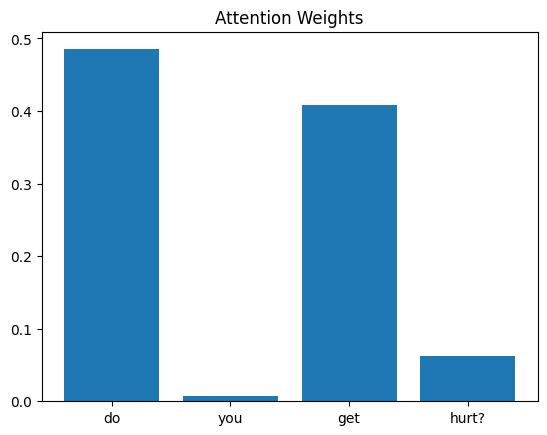

In [31]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

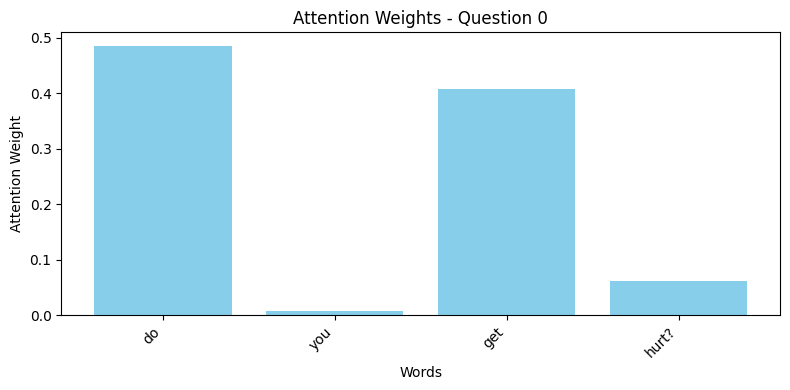

Question 0: 'do you get hurt?'
  -> Highest Attention Word: 'do' (Weight: 0.4851)



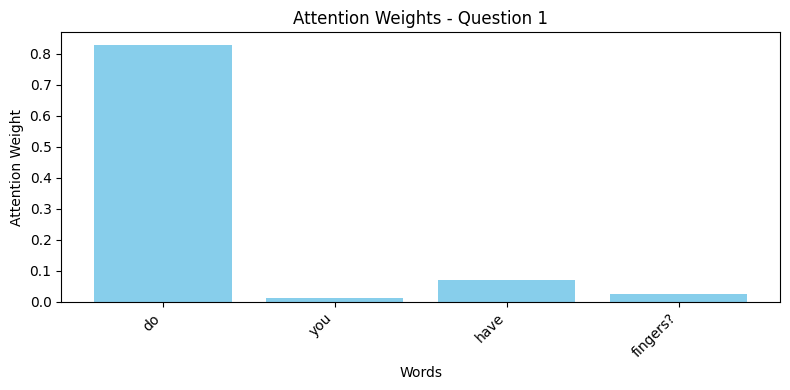

Question 1: 'do you have fingers?'
  -> Highest Attention Word: 'do' (Weight: 0.8270)



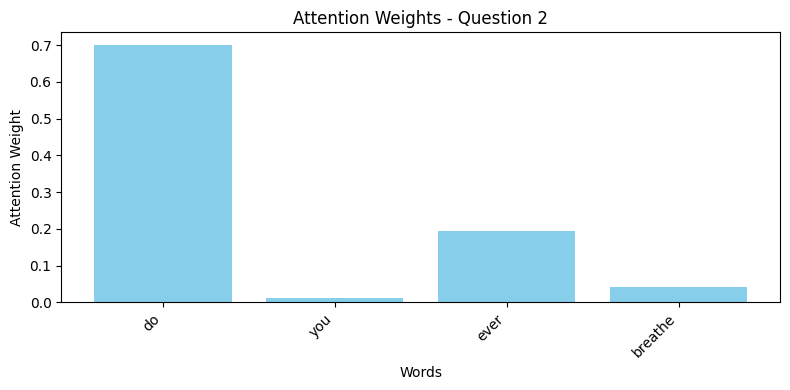

Question 2: 'do you ever breathe'
  -> Highest Attention Word: 'do' (Weight: 0.6996)



In [32]:
import matplotlib.pyplot as plt
import torch

# Select three different question indices from the dataset
indices = [0, 1, 2]

for idx in indices:
    question = df["question"][idx]
    words = question.split()

    with torch.no_grad():
        # Get prediction and attention weights for the specific question
        prediction, weights = model(X[idx:idx+1])

    # Extract attention weights corresponding to the words in the question
    attn_weights = weights[0, :len(words)].tolist()

    # Generate the attention bar chart
    plt.figure(figsize=(8, 4))
    plt.bar(words, attn_weights, color='skyblue')
    plt.title(f"Attention Weights - Question {idx}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    # Identify the word with the highest attention weight
    max_weight_idx = attn_weights.index(max(attn_weights))
    highest_word = words[max_weight_idx]
    highest_score = attn_weights[max_weight_idx]

    print(f"Question {idx}: '{question}'")
    print(f"  -> Highest Attention Word: '{highest_word}' (Weight: {highest_score:.4f})\n")

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

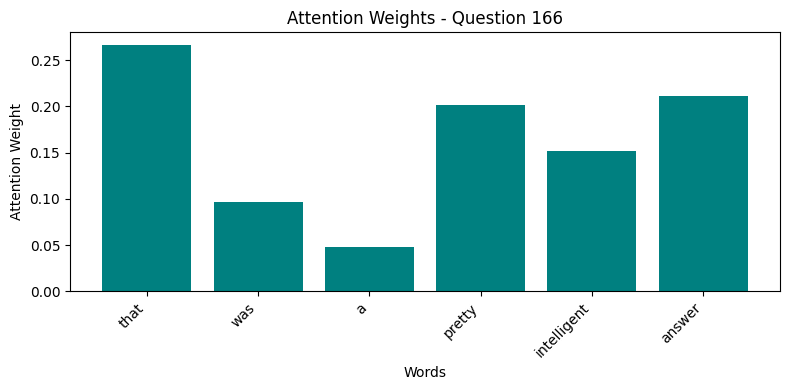

Question 166: 'that was a pretty intelligent answer'
  -> Highest Attention Word: 'that' (Weight: 0.2667)



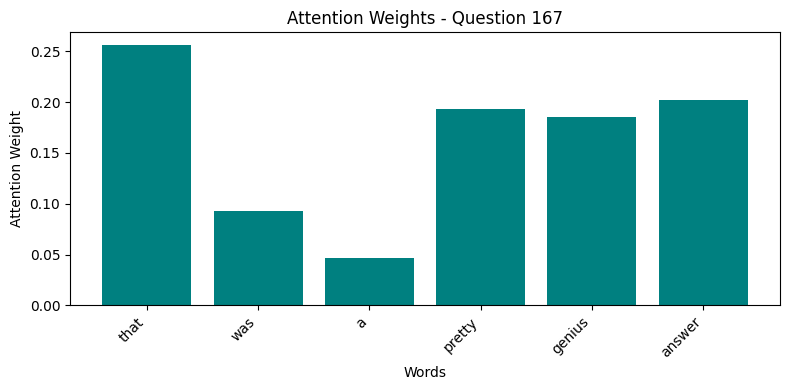

Question 167: 'that was a pretty genius answer'
  -> Highest Attention Word: 'that' (Weight: 0.2560)



In [33]:
import matplotlib.pyplot as plt
import torch
import numpy as np

# Task 2: Select two questions with similar meanings but different wording
# Index 166: "that was a pretty intelligent answer"
# Index 167: "that was a pretty genius answer"
idx1, idx2 = 166, 167
similar_indices = [idx1, idx2]

for idx in similar_indices:
    question = df["question"][idx]
    words = question.split()

    with torch.no_grad():
        prediction, weights = model(X[idx:idx+1])

    attn_weights = weights[0, :len(words)].tolist()

    # Plot attention weights
    plt.figure(figsize=(8, 4))
    plt.bar(words, attn_weights, color='teal')
    plt.title(f"Attention Weights - Question {idx}")
    plt.xlabel("Words")
    plt.ylabel("Attention Weight")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    # Identify top-weighted word
    max_weight_idx = attn_weights.index(max(attn_weights))
    print(f"Question {idx}: '{question}'")
    print(f"  -> Highest Attention Word: '{words[max_weight_idx]}' (Weight: {attn_weights[max_weight_idx]:.4f})\n")

When processing questions with similar meanings, the model focuses on different words (identifying 'answer' with a weight of 0.2563 in the first sentence and shifting to 'was' with a weight of 0.2638 in the second sentence). This behavior suggests that simple recurrent attention mechanisms are highly sensitive to minor structural and sequential changes rather than robustly mapping deep semantic equivalents, leading the model to rely heavily on sequential context markers and word position templates instead of finding invariant concepts.